# ML Preprocessing and Feature Engineering

Prepare the cleaned PHA asteroid data for binary classification of `pha`. Run the cells in order. Identifiers and variables that directly encode the PHA classification criteria are excluded to reduce target leakage. Preprocessing is fitted on the training split only.

## 1. Imports and file paths

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.special import boxcox as boxcox_transform
from scipy.stats import boxcox_normmax
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, StandardScaler

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "Data" / "pha_dataset_cleaned.csv").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_PATH = PROJECT_ROOT / "Data" / "pha_dataset_cleaned.csv"
IMPORTANCE_PATH = PROJECT_ROOT / "Data" / "pha_feature_importance.csv"
TARGET = "pha"
RANDOM_STATE = 42
print("Input:", DATA_PATH)

Input: d:\Guvi\PDA\Data\pha_dataset_cleaned.csv


## 2. Load data and inspect the target

In [2]:
df = pd.read_csv(DATA_PATH, low_memory=False)
print(f"Dataset shape: {df.shape[0]:,} rows x {df.shape[1]} columns")
display(df[TARGET].value_counts(dropna=False).to_frame("count"))

Dataset shape: 958,524 rows x 45 columns


,count
pha,
N,956458
Y,2066


## 3. Encode the target label

In [3]:
df = df.dropna(subset=[TARGET]).copy()
target_encoder = LabelEncoder()
y = pd.Series(
    target_encoder.fit_transform(df[TARGET].astype(str).str.strip().str.upper()),
    index=df.index,
    name=TARGET,
)
print("Target encoding:", dict(zip(target_encoder.classes_, target_encoder.transform(target_encoder.classes_))))
display(y.value_counts().sort_index().rename("count").to_frame())

Target encoding: {'N': np.int64(0), 'Y': np.int64(1)}


,count
pha,
0,956458
1,2066


## 4. Select features and avoid target leakage

Identifiers/names do not represent measurements. `neo`, `moid`, `moid_ld`, and `H` are excluded because they directly or indirectly encode PHA classification criteria.

In [4]:
excluded_columns = {
    TARGET, "id", "spkid", "pdes", "name", "full_name", "prefix", "orbit_id",
    "neo", "moid", "moid_ld", "H",
}
feature_columns = [column for column in df.columns if column not in excluded_columns]
X = df[feature_columns].copy()
numeric_columns = X.select_dtypes(include="number").columns.tolist()
categorical_columns = X.select_dtypes(include=["object", "string", "category"]).columns.tolist()
unsupported_columns = [column for column in X.columns if column not in numeric_columns + categorical_columns]
if unsupported_columns:
    raise TypeError(f"Unsupported feature types: {unsupported_columns}")
print(f"Numeric features ({len(numeric_columns)}): {numeric_columns}")
print(f"Categorical features ({len(categorical_columns)}): {categorical_columns}")
print("Missing values in selected features:", int(X.isna().sum().sum()))

Numeric features (31): ['diameter', 'albedo', 'diameter_sigma', 'epoch', 'epoch_mjd', 'epoch_cal', 'e', 'a', 'q', 'i', 'om', 'w', 'ma', 'ad', 'n', 'tp', 'tp_cal', 'per', 'per_y', 'sigma_e', 'sigma_a', 'sigma_q', 'sigma_i', 'sigma_om', 'sigma_w', 'sigma_ma', 'sigma_ad', 'sigma_n', 'sigma_tp', 'sigma_per', 'rms']
Categorical features (2): ['equinox', 'class']
Missing values in selected features: 0


## 5. Stratified train-test split

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
print(f"Training rows: {len(X_train):,}; test rows: {len(X_test):,}")
display(pd.concat([
    y_train.value_counts(normalize=True).rename("train_proportion"),
    y_test.value_counts(normalize=True).rename("test_proportion"),
], axis=1))

Training rows: 766,819; test rows: 191,705


,train_proportion,test_proportion
pha,,
0,0.997844,0.997846
1,0.002156,0.002154


## 6. Measure skewness and detect outliers

In [6]:
skewness = X_train[numeric_columns].skew().sort_values(ascending=False)
display(skewness.to_frame("skewness").head(20))

q1 = X_train[numeric_columns].quantile(0.25)
q3 = X_train[numeric_columns].quantile(0.75)
iqr = q3 - q1
lower_bounds = q1 - 1.5 * iqr
upper_bounds = q3 + 1.5 * iqr
iqr_counts = ((X_train[numeric_columns] < lower_bounds) | (X_train[numeric_columns] > upper_bounds)).sum()
print("IQR outliers per feature:")
display(iqr_counts.sort_values(ascending=False).head(20).to_frame("outlier_count"))

# Z-score diagnostic on a reproducible sample for speed.
z_sample = X_train[numeric_columns].sample(n=min(20_000, len(X_train)), random_state=RANDOM_STATE)
z_mean = X_train[numeric_columns].mean()
z_std = X_train[numeric_columns].std().replace(0, np.nan)
z_counts = ((z_sample - z_mean).abs().div(z_std) > 3).sum()
print("Sample values with absolute Z-score > 3:")
display(z_counts.sort_values(ascending=False).head(20).to_frame("sample_count"))

,skewness
per,874.125218
per_y,874.125218
rms,874.005879
sigma_tp,871.219547
sigma_ma,870.306380
sigma_w,870.305659
ad,844.222114
sigma_om,756.179349
sigma_ad,747.555729
sigma_a,715.790147


IQR outliers per feature:


,outlier_count
sigma_e,162002
sigma_q,159639
sigma_n,154587
sigma_ma,153206
sigma_ad,153056
sigma_a,152371
sigma_per,152056
sigma_tp,151368
sigma_w,146070
sigma_i,133287


Sample values with absolute Z-score > 3:


,sample_count
albedo,572
epoch_mjd,507
epoch,507
epoch_cal,473
e,322
i,220
n,219
diameter_sigma,171
tp_cal,163
tp,162


## 7. Cap outliers and transform skewed features

IQR limits are computed from training data and applied to both splits. Positive skewed features use Box-Cox; non-negative skewed features containing zero use `log1p`. Box-Cox parameters are learned from the training sample only.

In [7]:
boxcox_columns = [column for column in numeric_columns if skewness[column] > 1 and X_train[column].min() > 0]
log_columns = [column for column in numeric_columns if skewness[column] > 1 and X_train[column].min() == 0]
print("Box-Cox features:", boxcox_columns)
print("log1p features:", log_columns)

X_train_fe = X_train.copy()
X_test_fe = X_test.copy()
for column in numeric_columns:
    cap_lower = lower_bounds[column]
    if column in boxcox_columns:
        # Box-Cox requires values to remain strictly positive after capping.
        cap_lower = max(cap_lower, X_train[column].min())
    X_train_fe[column] = X_train_fe[column].clip(lower=cap_lower, upper=upper_bounds[column])
    X_test_fe[column] = X_test_fe[column].clip(lower=cap_lower, upper=upper_bounds[column])

boxcox_lambdas = {}
for column in boxcox_columns:
    fit_sample = X_train_fe[column].sample(n=min(20_000, len(X_train_fe)), random_state=RANDOM_STATE)
    fitted_lambda = boxcox_normmax(fit_sample.to_numpy(), method="mle")
    boxcox_lambdas[column] = fitted_lambda
    X_train_fe[column] = boxcox_transform(X_train_fe[column].to_numpy(), fitted_lambda)
    X_test_fe[column] = boxcox_transform(X_test_fe[column].to_numpy(), fitted_lambda)

for column in log_columns:
    X_train_fe[column] = np.log1p(X_train_fe[column].clip(lower=0))
    X_test_fe[column] = np.log1p(X_test_fe[column].clip(lower=0))
print(f"Capped {len(numeric_columns)} numeric columns; Box-Cox: {len(boxcox_columns)}; log1p: {len(log_columns)}")

Box-Cox features: ['diameter', 'albedo', 'diameter_sigma', 'q', 'i', 'ad', 'n', 'per', 'sigma_e', 'sigma_a', 'sigma_q', 'sigma_i', 'sigma_om', 'sigma_w', 'sigma_ma', 'sigma_ad', 'sigma_n', 'sigma_tp', 'sigma_per']
log1p features: ['e', 'per_y', 'rms']


c:\Users\nihaa\pandas\venv\Lib\site-packages\scipy\optimize\_optimize.py:3049: RuntimeWarning: invalid value encountered in scalar divide
  w = xb - ((xb - xc) * tmp2 - (xb - xa) * tmp1) / denom
c:\Users\nihaa\pandas\venv\Lib\site-packages\scipy\optimize\_optimize.py:2539: RuntimeWarning: invalid value encountered in scalar subtract
  tmp1 = (x - w) * (fx - fv)
c:\Users\nihaa\pandas\venv\Lib\site-packages\scipy\optimize\_optimize.py:2540: RuntimeWarning: invalid value encountered in scalar subtract
  tmp2 = (x - v) * (fx - fw)


Capped 31 numeric columns; Box-Cox: 19; log1p: 3


## 8. One-hot encode categories and scale numeric features

The encoder ignores categories not seen during training. `StandardScaler` and `OneHotEncoder` are fitted only on the training features to prevent test-data leakage.

In [8]:
preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", StandardScaler(), numeric_columns),
        ("categorical", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical_columns),
    ],
    remainder="drop",
    verbose_feature_names_out=False,
)
X_train_processed = preprocessor.fit_transform(X_train_fe)
X_test_processed = preprocessor.transform(X_test_fe)
processed_feature_names = preprocessor.get_feature_names_out()
print("Processed training shape:", X_train_processed.shape)
print("Processed test shape:", X_test_processed.shape)

Processed training shape: (766819, 45)
Processed test shape: (191705, 45)


## 9. Random Forest feature importance

Fit on up to 100,000 training rows to keep runtime manageable. Class weighting helps account for an imbalanced target. Importance is exploratory and should not replace evaluation on the held-out test data.

In [9]:
importance_sample_size = min(100_000, len(y_train))
rng = np.random.default_rng(RANDOM_STATE)
importance_indices = np.sort(rng.choice(len(y_train), size=importance_sample_size, replace=False))

rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=18,
    min_samples_leaf=2,
    class_weight="balanced_subsample",
    random_state=RANDOM_STATE,
    n_jobs=-1,
)
rf_model.fit(X_train_processed[importance_indices], y_train.iloc[importance_indices])
feature_importance = pd.DataFrame({
    "feature": processed_feature_names,
    "importance": rf_model.feature_importances_,
}).sort_values("importance", ascending=False, ignore_index=True)
display(feature_importance.head(20))

,feature,importance
0,q,0.268962
1,class_MBA,0.153097
2,class_APO,0.143001
3,e,0.109305
4,n,0.055334
5,per,0.046330
6,per_y,0.042456
7,ad,0.038848
8,a,0.029482
9,rms,0.018719


## 10. Select and save the top features

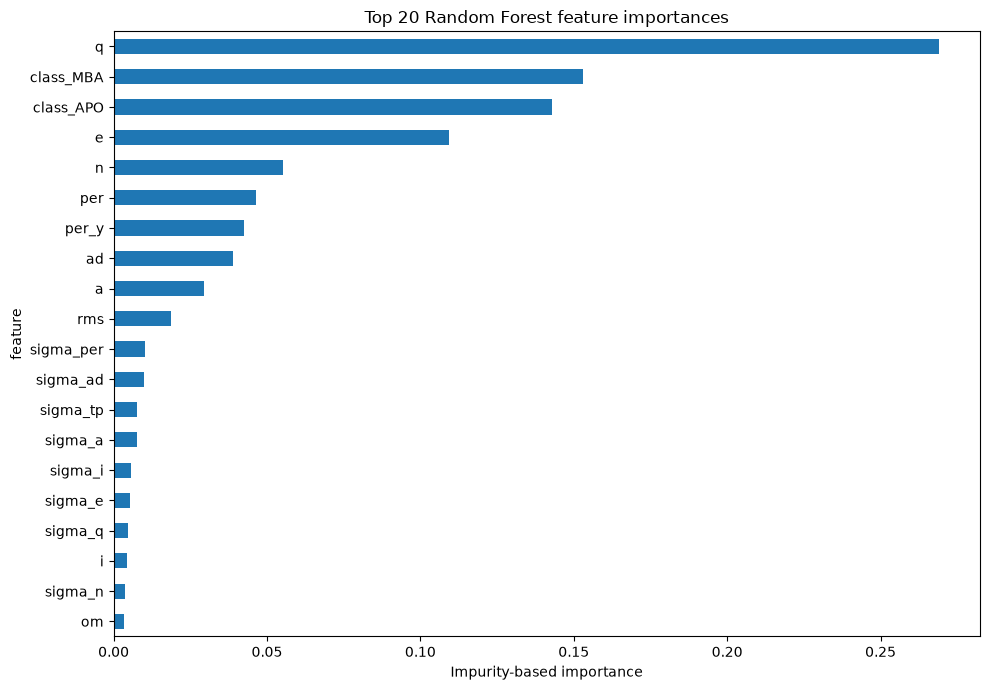

Saved feature importance: d:\Guvi\PDA\Data\pha_feature_importance.csv
Selected features: ['q', 'class_MBA', 'class_APO', 'e', 'n', 'per', 'per_y', 'ad', 'a', 'rms', 'sigma_per', 'sigma_ad', 'sigma_tp', 'sigma_a', 'sigma_i', 'sigma_e', 'sigma_q', 'i', 'sigma_n', 'om']
Use X_train_selected, X_test_selected, y_train, and y_test for the next modeling step.


In [10]:
TOP_N_FEATURES = min(20, len(processed_feature_names))
selected_feature_names = feature_importance.head(TOP_N_FEATURES)["feature"].tolist()
selected_feature_indices = [int(np.flatnonzero(processed_feature_names == feature)[0]) for feature in selected_feature_names]
X_train_selected = X_train_processed[:, selected_feature_indices]
X_test_selected = X_test_processed[:, selected_feature_indices]

top_features = feature_importance.head(TOP_N_FEATURES).sort_values("importance")
top_features.plot(
    x="feature", y="importance", kind="barh", legend=False, figsize=(10, 7),
    title=f"Top {TOP_N_FEATURES} Random Forest feature importances",
)
plt.xlabel("Impurity-based importance")
plt.tight_layout()
plt.show()

feature_importance.to_csv(IMPORTANCE_PATH, index=False)
print("Saved feature importance:", IMPORTANCE_PATH)
print("Selected features:", selected_feature_names)
print("Use X_train_selected, X_test_selected, y_train, and y_test for the next modeling step.")